# IS403 - Walmart M5: ARIMA and Weekly SARIMA

Compare bounded ARIMA/SARIMA candidate sets on the audited Level 1 series.
Every forecast covers 28 days from one fixed origin. Only `train.csv` and
`val.csv` are opened. Test labels remain outside model selection.

Run all cells on Kaggle CPU with the same processed dataset as notebooks 00-02.
Paths are discovered automatically. No new inputs or package installation are
required in the standard Kaggle environment. Model fitting takes longer than
the baseline and diagnostic notebooks; progress is printed during the search.

The protocol is fixed before fitting:
1. Fit every candidate on Train and rank eligible candidates by Validation RMSSE.
2. Freeze the best eligible ARIMA and SARIMA configurations separately.
3. Evaluate those configurations on the same three development origins as
   the four baselines. This includes Validation and is a development stability
   check, not an independent cross-validation estimate.
4. Record AIC/BIC, convergence, coefficients, residual ACF and Ljung-Box results.

No claim of model adequacy follows solely from a successful numerical run.

In [1]:
from pathlib import Path
from importlib import metadata
from datetime import datetime, timezone
from time import perf_counter
from zipfile import ZipFile, ZIP_DEFLATED
from itertools import product
import hashlib
import json
import platform
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.graphics.gofplots import qqplot
from threadpoolctl import threadpool_limits

DATA_DIR = None
OUTPUT_DIR = None

SEED = 42
HORIZON = 28
SEASON_LENGTH = 7
MA_WINDOWS = (7, 28)
ORIGINS = (1829, 1857, 1885)
SALES_SCALE = 1000.0
MAX_ITERATIONS = (200, 400)
ALPHA = 0.05
LB_LAGS = (14, 21, 28)
random.seed(SEED)
np.random.seed(SEED)
RUN_STARTED = perf_counter()

## 1. Verify the development inputs and forecast origins

The fingerprints cover every value of the original 14-column Train/Validation
tables. The three target blocks end before Test. Input features other than
sales are retained for validation of the handoff, but are not used by these
univariate ARIMA/SARIMA models.

In [2]:
FILENAMES = ('train.csv', 'val.csv')


def find_data_directory(override=None):
    if override is not None:
        selected = Path(override).expanduser().resolve()
        if not all((selected / name).is_file() for name in FILENAMES):
            raise FileNotFoundError(f'Expected train.csv and val.csv in: {selected}')
        return selected

    candidates = set()
    for directory in [Path.cwd(), Path.cwd() / 'dataset',
                      Path.cwd() / '02_Data' / 'processed']:
        if all((directory / name).is_file() for name in FILENAMES):
            candidates.add(directory.resolve())

    root = Path('/kaggle/input')
    if root.is_dir():
        for path in root.rglob('train.csv'):
            if all((path.parent / name).is_file() for name in FILENAMES):
                candidates.add(path.parent.resolve())

    if not candidates:
        raise FileNotFoundError(
            'Attach the processed Kaggle dataset containing train.csv and val.csv, '
            'or set DATA_DIR explicitly.'
        )
    if len(candidates) > 1:
        options = '\n'.join(str(path) for path in sorted(candidates))
        raise ValueError(f'Multiple datasets found. Set DATA_DIR explicitly:\n{options}')
    return candidates.pop()


data_dir = find_data_directory(DATA_DIR)
output_dir = Path(OUTPUT_DIR) if OUTPUT_DIR is not None else (
    Path('/kaggle/working') if Path('/kaggle/working').is_dir()
    else Path.cwd() / 'arima_output'
)
print(f'Data: {data_dir}')
print(f'Output: {output_dir.resolve()}')

Data: /kaggle/input/datasets/nhntrnc/is403-m5-level-1
Output: /kaggle/working


In [3]:
EXPECTED_COLUMNS = ['d', 'date', 'total_sales', 'weekday', 'wday_iso', 'month', 'year', 'event_name_1', 'event_type_1', 'event_name_2', 'event_type_2', 'snap_CA', 'snap_TX', 'snap_WI']
NUMERIC_COLUMNS = ['total_sales', 'wday_iso', 'month', 'year', 'snap_CA', 'snap_TX', 'snap_WI']
EVENT_COLUMNS = ['event_name_1', 'event_type_1', 'event_name_2', 'event_type_2']
REFERENCE_SHA256 = {'train': 'dcb9407590b16f6b975a1647c1c20f3cb932bc78dd75c1637f94d313c599d271', 'val': 'fbee2683fca3c5fc731b1d81829a56aa12c71e5b70ad124a1ac01ab3754536b5'}
SPLIT_DAYS = {'train': (1, 1885), 'val': (1886, 1913)}
FIRST_DATE = pd.Timestamp('2011-01-29')


def require(condition, message):
    if not condition:
        raise ValueError(message)


def table_sha256(frame):
    canonical_csv = frame[EXPECTED_COLUMNS].to_csv(index=False, lineterminator='\n')
    return hashlib.sha256(canonical_csv.encode('utf-8')).hexdigest()


def validate_split(name, directory):
    path = directory / f'{name}.csv'
    frame = pd.read_csv(path, keep_default_na=False)
    require(list(frame.columns) == EXPECTED_COLUMNS,
            f'{name}: columns or column order differ from the audited dataset.')

    first, last = SPLIT_DAYS[name]
    require(len(frame) == last - first + 1, f'{name}: incorrect row count.')
    require(frame['d'].tolist() == [f'd_{day}' for day in range(first, last + 1)],
            f'{name}: day IDs are missing, duplicated, or out of order.')
    dates = pd.to_datetime(frame['date'], format='%Y-%m-%d', errors='raise')
    expected_dates = pd.date_range(FIRST_DATE + pd.Timedelta(days=first - 1),
                                   periods=len(frame), freq='D')
    require(pd.DatetimeIndex(dates).equals(expected_dates),
            f'{name}: dates do not match the fixed chronological split.')
    require(not frame.duplicated(['d']).any() and not dates.duplicated().any(),
            f'{name}: duplicate day or date.')
    frame['date'] = dates.dt.strftime('%Y-%m-%d')

    for column in NUMERIC_COLUMNS:
        values = pd.to_numeric(frame[column], errors='raise')
        require(bool(np.isfinite(values.to_numpy()).all()),
                f'{name}: {column} contains missing or non-finite values.')
        require(bool((values % 1 == 0).all()), f'{name}: {column} must contain integers.')
        frame[column] = values.astype(np.int64)

    require(bool((frame['total_sales'] >= 0).all()), f'{name}: negative sales.')
    require(np.array_equal(frame['wday_iso'], dates.dt.dayofweek + 1),
            f'{name}: incorrect ISO weekday (Monday=1).')
    require(np.array_equal(frame['month'], dates.dt.month), f'{name}: incorrect month.')
    require(np.array_equal(frame['year'], dates.dt.year), f'{name}: incorrect year.')
    require(frame['weekday'].tolist() == dates.dt.day_name().tolist(),
            f'{name}: incorrect weekday names.')
    for column in ['snap_CA', 'snap_TX', 'snap_WI']:
        require(bool(frame[column].isin([0, 1]).all()), f'{name}: {column} is not binary.')
    for column in EVENT_COLUMNS:
        require(bool(frame[column].map(lambda value: isinstance(value, str)
                     and bool(value.strip())).all()),
                f'{name}: empty event labels; expected the literal string None.')

    fingerprint = table_sha256(frame)
    require(fingerprint == REFERENCE_SHA256[name],
            f'{name}: table values differ from the audited handoff. '
            'Use the audited original processed CSV files.')
    inventory = {
        'file': path.name,
        'rows': len(frame),
        'columns': len(frame.columns),
        'first_day': frame['d'].iloc[0],
        'last_day': frame['d'].iloc[-1],
        'first_date': frame['date'].iloc[0],
        'last_date': frame['date'].iloc[-1],
        'table_sha256': fingerprint,
        'matches_audited_handoff': True,
    }
    return frame, inventory

In [4]:
frames = {}
input_inventory = []
for split in SPLIT_DAYS:
    frames[split], record = validate_split(split, data_dir)
    input_inventory.append(record)

development = pd.concat([frames['train'], frames['val']], ignore_index=True)
require(len(development) == 1913, 'Expected exactly 1,913 development days.')
require(development['d'].tolist() == [f'd_{day}' for day in range(1, 1914)],
        'Development data must be consecutive and end at d_1913.')
development['date'] = pd.to_datetime(development['date'])

fold_plan = pd.DataFrame([
    {
        'fold': fold,
        'origin_day': f'd_{origin}',
        'origin_date': development.iloc[origin - 1]['date'].strftime('%Y-%m-%d'),
        'history_rows': origin,
        'forecast_start': development.iloc[origin]['date'].strftime('%Y-%m-%d'),
        'forecast_end': development.iloc[origin + HORIZON - 1]['date'].strftime('%Y-%m-%d'),
    }
    for fold, origin in enumerate(ORIGINS, start=1)
])
print(pd.DataFrame(input_inventory)[['file', 'rows', 'columns',
                                    'matches_audited_handoff']].to_string(index=False))
print(fold_plan.to_string(index=False))
print('PASS: development data verified; test.csv has not been read.')

     file  rows  columns  matches_audited_handoff
train.csv  1885       14                     True
  val.csv    28       14                     True
 fold origin_day origin_date  history_rows forecast_start forecast_end
    1     d_1829  2016-01-31          1829     2016-02-01   2016-02-28
    2     d_1857  2016-02-28          1857     2016-02-29   2016-03-27
    3     d_1885  2016-03-27          1885     2016-03-28   2016-04-24
PASS: development data verified; test.csv has not been read.


## 2. Retain the same baselines and scoring rules

RMSSE is the primary metric; MAE and RMSE are secondary. Each fold uses the
mean squared first differences of its own observed prefix as the RMSSE scale.
The final fold uses the original 1,885-day Train scale, exactly as notebook 01.
Naive, Seasonal Naive 7, SMA-7 and SMA-28 are all retained.

ARIMA fitting uses sales divided by the fixed constant 1,000 to improve numerical
scaling. This is a unit conversion, not a fitted scaler. Forecasts and reported
errors are converted back to original units. Negative point forecasts are
clipped to zero before scoring, with the count and fraction recorded.

In [5]:
CONFIGS = [
    {'model': 'Naive', 'config_id': 'naive', 'window': 0, 'season_length': 0},
    {'model': 'Seasonal Naive', 'config_id': 'seasonal_naive_7',
     'window': 0, 'season_length': SEASON_LENGTH},
] + [
    {'model': 'Moving Average', 'config_id': f'moving_average_{window}',
     'window': window, 'season_length': 0}
    for window in MA_WINDOWS
]


def predict_baseline(history, config, horizon=HORIZON):
    """Return a fixed-origin forecast using observed history only."""
    history = np.asarray(history, dtype=np.float64)
    require(history.ndim == 1 and len(history) >= 2,
            'History must be a one-dimensional series with at least two observations.')
    require(np.isfinite(history).all(), 'History must contain finite values.')
    require(horizon > 0, 'Forecast horizon must be positive.')

    if config['model'] == 'Naive':
        prediction = np.full(horizon, history[-1], dtype=np.float64)
    elif config['model'] == 'Seasonal Naive':
        period = config['season_length']
        require(0 < period <= len(history), 'Invalid seasonal period.')
        prediction = np.tile(history[-period:], int(np.ceil(horizon / period)))[:horizon]
    elif config['model'] == 'Moving Average':
        window = config['window']
        require(0 < window <= len(history), 'Invalid averaging window.')
        prediction = np.full(horizon, history[-window:].mean(), dtype=np.float64)
    else:
        raise ValueError(f'Unknown model: {config["model"]}')

    require(prediction.shape == (horizon,) and np.isfinite(prediction).all(),
            'The forecast must contain exactly one finite value per target day.')
    clipped_count = int((prediction < 0).sum())
    return np.maximum(prediction, 0.0), clipped_count


def score_forecast(actual, prediction, history):
    actual = np.asarray(actual, dtype=np.float64)
    prediction = np.asarray(prediction, dtype=np.float64)
    history = np.asarray(history, dtype=np.float64)
    require(actual.shape == prediction.shape == (HORIZON,),
            'Each evaluation block must contain exactly 28 actuals and forecasts.')
    require(np.isfinite(actual).all() and np.isfinite(prediction).all(),
            'Scoring inputs must be finite.')
    require(history.ndim == 1 and len(history) >= 2 and np.isfinite(history).all(),
            'The RMSSE history must be a finite one-dimensional prefix.')
    scale = float(np.mean(np.diff(history) ** 2))
    require(np.isfinite(scale) and scale > 0, 'The RMSSE denominator must be positive.')
    error = actual - prediction
    mse = float(np.mean(error ** 2))
    return {
        'rmsse': float(np.sqrt(mse / scale)),
        'mae': float(np.mean(np.abs(error))),
        'rmse': float(np.sqrt(mse)),
        'rmsse_scale': scale,
    }

## 3. Specify a bounded candidate search

Notebook 02 found nonstationarity in the original Train series with both
constant-only and trend specifications. Ordinary and weekly differences were
supported by the paired ADF/KPSS tests. Weekly ACF structure remained after
ordinary differencing; the combined difference also had a notable negative
lag-one ACF. These findings motivate alternatives rather than forcing both
differences in every model.

- ARIMA: d=1; p in {0,1,2,7}; q in {0,1,2}; with and without drift.
  Integer p=7 includes AR lags 1 through 7 and is evaluated explicitly.
- SARIMA: s=7; (d,D) in {(1,0),(0,1),(1,1)}; eight low-order AR/MA patterns
  listed below. The patterns emphasize seasonal MA(1), with seasonal AR(1)
  alternatives. This is a purposeful bounded search, not the full Cartesian grid.
- A linear deterministic trend (`t`) supplies drift when d+D=1. Combined
  differencing uses no deterministic trend to avoid a quadratic level trend.

There are 24 ARIMA and 40 SARIMA candidates. The smaller orders and the explicit
p=7 extension keep the experiment feasible while checking the weekly structure.
The search is not claimed to exhaust every possible ARIMA specification.

AIC/BIC are recorded on the same rescaled target. Compare them within a fixed
(d,D) specification; they are not used to rank different differencing orders.
Selection uses Validation RMSSE, then parameter count and configuration ID for
exact ties. Candidates that fail convergence or finite-output checks are logged
and excluded, without invented scores.

In [6]:
def make_candidate(family, p, d, q, P=0, D=0, Q=0, trend='n'):
    s = SEASON_LENGTH if family == 'SARIMA' else 0
    parts = [p, d, q] if family == 'ARIMA' else [p, d, q, P, D, Q, s]
    config_id = family.lower() + '_' + '_'.join(map(str, parts)) + '_' + trend
    return {'family': family, 'config_id': config_id, 'p': p, 'd': d, 'q': q,
            'P': P, 'D': D, 'Q': Q, 's': s, 'trend': trend}


candidates = [make_candidate('ARIMA', p, 1, q, trend=trend)
              for p, q, trend in product([0, 1, 2, 7], [0, 1, 2], ['n', 't'])]
seasonal_patterns = [
    (0, 0, 0, 1), (1, 0, 0, 1), (0, 1, 0, 1), (1, 1, 0, 1),
    (2, 0, 0, 1), (0, 2, 0, 1), (1, 1, 1, 0), (1, 1, 1, 1),
]
for d, D in [(1, 0), (0, 1), (1, 1)]:
    trends = ['n', 't'] if d + D == 1 else ['n']
    for (p, q, P, Q), trend in product(seasonal_patterns, trends):
        candidates.append(make_candidate('SARIMA', p, d, q, P, D, Q, trend))
candidate_plan = pd.DataFrame(candidates)
require(len(candidate_plan) == 64 and candidate_plan['config_id'].is_unique,
        'Expected 64 unique statistical candidates.')
require(len(candidate_plan[(candidate_plan['family'] == 'ARIMA')
                           & (candidate_plan['p'] == 7)]) == 6,
        'The explicit p=7 ARIMA candidates are missing.')
print(candidate_plan.groupby(['family', 'd', 'D']).size().rename('candidates').to_string())
print('SARIMA patterns (p, q, P, Q):')
print(pd.DataFrame(seasonal_patterns, columns=['p', 'q', 'P', 'Q']).to_string(index=False))

family  d  D
ARIMA   1  0    24
SARIMA  0  1    16
        1  0    16
           1     8
SARIMA patterns (p, q, P, Q):
 p  q  P  Q
 0  0  0  1
 1  0  0  1
 0  1  0  1
 1  1  0  1
 2  0  0  1
 0  2  0  1
 1  1  1  0
 1  1  1  1


## 4. Fit candidates and select on Validation

The forecasting function receives only the observed prefix. Actual future
sales are used afterwards for scoring. Maximum-likelihood state-space fitting
enforces stationary AR and invertible MA components, conditional on the
specified differencing. The optimizer uses one numerical-library thread.

Each fit starts with 200 L-BFGS iterations. A nonconverged fit is retried once
for up to 400 iterations from its latest finite parameters. Both attempts and
all captured warnings are recorded. This retry changes numerical optimization,
not the model specification. A warning or residual diagnostic rejection is not
silently converted into a successful model-adequacy claim.

In [7]:
def fit_candidate(history, config):
    observed = np.asarray(history, dtype=np.float64)
    require(observed.ndim == 1 and len(observed) >= 100,
            'ARIMA requires a one-dimensional observed training prefix.')
    require(np.isfinite(observed).all(), 'Non-finite training observations.')
    started = perf_counter()
    messages = []
    fitted = None
    attempts = 0
    result = {'eligible': False, 'converged': False, 'attempts': 0,
              'fit_seconds': 0.0, 'aic': None, 'bic': None,
              'parameter_count': None, 'clipped_count': None,
              'clipped_fraction': None, 'warnings': '', 'error': ''}
    try:
        model = ARIMA(observed / SALES_SCALE,
                      order=(config['p'], config['d'], config['q']),
                      seasonal_order=(config['P'], config['D'], config['Q'], config['s']),
                      trend=config['trend'], enforce_stationarity=True,
                      enforce_invertibility=True)
        start_params = None
        for attempts, maxiter in enumerate(MAX_ITERATIONS, start=1):
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter('always')
                with threadpool_limits(limits=1):
                    fitted = model.fit(
                        start_params=start_params, method='statespace', cov_type='opg',
                        method_kwargs={'method': 'lbfgs', 'maxiter': maxiter, 'disp': False})
            messages.extend(f"attempt {attempts}: {type(w.message).__name__}: {w.message}"
                            for w in caught)
            result['converged'] = bool(fitted.mle_retvals.get('converged', False))
            if result['converged']:
                break
            if not np.isfinite(fitted.params).all():
                break
            start_params = fitted.params
        result.update(aic=float(fitted.aic), bic=float(fitted.bic),
                      parameter_count=int(len(fitted.params)))
        require(result['converged'], 'Optimizer did not converge after the allowed attempts.')
        require(np.isfinite(fitted.params).all()
                and np.isfinite([fitted.aic, fitted.bic]).all(),
                'Non-finite fitted parameters or information criteria.')
        raw = np.asarray(fitted.forecast(steps=HORIZON), dtype=np.float64) * SALES_SCALE
        require(raw.shape == (HORIZON,) and np.isfinite(raw).all(),
                'The forecast must have 28 finite values.')
        clipped = int((raw < 0).sum())
        result.update(eligible=True, clipped_count=clipped,
                      clipped_fraction=clipped / HORIZON)
        prediction = np.maximum(raw, 0.0)
    except Exception as error:
        result['error'] = f'{type(error).__name__}: {error}'
        prediction = None
    result.update(attempts=attempts, fit_seconds=float(perf_counter() - started),
                  warnings=' | '.join(dict.fromkeys(messages)))
    return fitted, prediction, result


history = frames['train']['total_sales'].to_numpy(dtype=np.float64)
actual = frames['val']['total_sales'].to_numpy(dtype=np.float64)
search_rows = []
best_validation = {}
for index, config in enumerate(candidates, start=1):
    fitted, prediction, fit_info = fit_candidate(history, config)
    row = {**config, 'origin_day': 'd_1885', 'history_rows': len(history), **fit_info,
           'rmsse': None, 'mae': None, 'rmse': None, 'rmsse_scale': None}
    if fit_info['eligible']:
        row.update(score_forecast(actual, prediction, history))
        key = (row['rmsse'], row['parameter_count'], row['config_id'])
        incumbent = best_validation.get(config['family'])
        if incumbent is None or key < incumbent['ranking_key']:
            best_validation[config['family']] = {
                'config': config.copy(), 'fit': fitted, 'prediction': prediction.copy(),
                'fit_info': fit_info.copy(), 'ranking_key': key}
    search_rows.append(row)
    state = f"RMSSE={row['rmsse']:.4f}" if row['eligible'] else 'excluded; see search log'
    print(f"[{index:02d}/{len(candidates)}] {config['config_id']}: {state}", flush=True)

search_results = pd.DataFrame(search_rows)
require(set(best_validation) == {'ARIMA', 'SARIMA'},
        'At least one eligible candidate is required in each model family.')
eligible_search = search_results[search_results['eligible']].copy()
eligible_search['aic_rank_within_d_D'] = eligible_search.groupby(
    ['family', 'd', 'D'])['aic'].rank(method='min')
eligible_search['bic_rank_within_d_D'] = eligible_search.groupby(
    ['family', 'd', 'D'])['bic'].rank(method='min')
search_results = search_results.merge(
    eligible_search[['config_id', 'aic_rank_within_d_D', 'bic_rank_within_d_D']],
    on='config_id', how='left', validate='one_to_one')
print('Selected by Validation RMSSE:')
selected_ids = [best_validation[family]['config']['config_id'] for family in ['ARIMA', 'SARIMA']]
print(search_results[search_results['config_id'].isin(selected_ids)]
      [['family', 'config_id', 'rmsse', 'mae', 'rmse', 'aic', 'bic']]
      .round(4).to_string(index=False))
print('Explicit p=7 ARIMA comparison:')
print(search_results[(search_results['family'] == 'ARIMA') & (search_results['p'] == 7)]
      [['config_id', 'eligible', 'rmsse', 'converged']].to_string(index=False))

[01/64] arima_0_1_0_n: RMSSE=1.3843
[02/64] arima_0_1_0_t: RMSSE=1.3923
[03/64] arima_0_1_1_n: RMSSE=1.3146
[04/64] arima_0_1_1_t: RMSSE=1.3206
[05/64] arima_0_1_2_n: RMSSE=1.2141
[06/64] arima_0_1_2_t: RMSSE=1.2058
[07/64] arima_1_1_0_n: RMSSE=1.3483
[08/64] arima_1_1_0_t: RMSSE=1.3554
[09/64] arima_1_1_1_n: RMSSE=1.2551
[10/64] arima_1_1_1_t: RMSSE=1.2430
[11/64] arima_1_1_2_n: RMSSE=1.2261
[12/64] arima_1_1_2_t: RMSSE=1.2152
[13/64] arima_2_1_0_n: RMSSE=1.3245
[14/64] arima_2_1_0_t: RMSSE=1.3317
[15/64] arima_2_1_1_n: RMSSE=1.1697
[16/64] arima_2_1_1_t: RMSSE=1.1628
[17/64] arima_2_1_2_n: RMSSE=1.1063
[18/64] arima_2_1_2_t: RMSSE=1.1029
[19/64] arima_7_1_0_n: RMSSE=0.6665
[20/64] arima_7_1_0_t: RMSSE=0.6615
[21/64] arima_7_1_1_n: RMSSE=0.6286
[22/64] arima_7_1_1_t: RMSSE=0.6257
[23/64] arima_7_1_2_n: RMSSE=0.6022
[24/64] arima_7_1_2_t: RMSSE=0.5982
[25/64] sarima_0_1_0_0_0_1_7_n: RMSSE=1.2011
[26/64] sarima_0_1_0_0_0_1_7_t: RMSSE=1.2081
[27/64] sarima_1_1_0_0_0_1_7_n: RMSSE=1.2909
[

## 5. Check the frozen configurations on three development windows

The selected model orders and deterministic terms remain fixed across origins.
Each origin is fitted from its own observed history; no fitted parameters or
future actuals are carried backwards from the Validation fit. The Validation
forecast is reused exactly from the search. Baseline definitions and RMSSE
scales match notebook 01. The stability summary includes the selection window
and should not be described as an unbiased final performance estimate.

In [8]:
score_rows = []
prediction_frames = []


def record_evaluation(model_name, config_id, fold, origin, prediction, fit_info):
    observed = development.iloc[:origin]['total_sales'].to_numpy(dtype=np.float64)
    target = development.iloc[origin:origin + HORIZON]
    actual = target['total_sales'].to_numpy(dtype=np.float64)
    require(len(actual) == HORIZON and target['date'].min() > development.iloc[origin - 1]['date'],
            'Targets must strictly follow the observed prefix.')
    require(np.isfinite(prediction).all() and (prediction >= 0).all(),
            'Invalid nonnegative forecast.')
    score_rows.append({
        'model': model_name, 'config_id': config_id, 'fold': fold,
        'origin_day': f'd_{origin}', 'history_rows': origin, 'horizon': HORIZON,
        'forecast_start': target['date'].iloc[0].strftime('%Y-%m-%d'),
        'forecast_end': target['date'].iloc[-1].strftime('%Y-%m-%d'),
        **score_forecast(actual, prediction, observed), **fit_info,
    })
    prediction_frames.append(pd.DataFrame({
        'model': model_name, 'config_id': config_id, 'fold': fold,
        'origin_day': f'd_{origin}', 'horizon_step': np.arange(1, HORIZON + 1),
        'd': target['d'].to_numpy(), 'date': target['date'].dt.strftime('%Y-%m-%d').to_numpy(),
        'actual': actual, 'prediction': prediction,
    }))


baseline_names = {'naive': 'Naive', 'seasonal_naive_7': 'Seasonal Naive 7',
                  'moving_average_7': 'SMA-7', 'moving_average_28': 'SMA-28'}
for fold, origin in enumerate(ORIGINS, start=1):
    history = development.iloc[:origin]['total_sales'].to_numpy(dtype=np.float64)
    for config in CONFIGS:
        started = perf_counter()
        prediction, clipped = predict_baseline(history, config)
        record_evaluation(baseline_names[config['config_id']], config['config_id'], fold,
                          origin, prediction, {'eligible': True, 'converged': True,
                          'fit_seconds': float(perf_counter() - started), 'attempts': 0,
                          'clipped_count': clipped, 'clipped_fraction': clipped / HORIZON,
                          'aic': None, 'bic': None, 'parameter_count': None,
                          'warnings': '', 'error': ''})
    for family in ['ARIMA', 'SARIMA']:
        chosen = best_validation[family]
        if fold == len(ORIGINS):
            prediction, fit_info = chosen['prediction'], chosen['fit_info']
        else:
            _, prediction, fit_info = fit_candidate(history, chosen['config'])
        require(fit_info['eligible'],
                f"{family} failed at origin d_{origin}: {fit_info['error']}")
        record_evaluation(family, chosen['config']['config_id'], fold,
                          origin, prediction, fit_info)
    print(f'Completed development fold {fold}/{len(ORIGINS)} at d_{origin}.', flush=True)

cv_scores = pd.DataFrame(score_rows)
predictions = pd.concat(prediction_frames, ignore_index=True)
require(len(cv_scores) == 18 and len(predictions) == 504,
        'Expected six models, three origins and 28 forecasts per model-origin.')
require(not predictions.duplicated(['config_id', 'fold', 'horizon_step']).any(),
        'Duplicate forecasts found.')
summary = cv_scores.groupby(['model', 'config_id'], as_index=False).agg(
    mean_rmsse=('rmsse', 'mean'), std_rmsse=('rmsse', 'std'),
    mean_mae=('mae', 'mean'), mean_rmse=('rmse', 'mean'), folds=('fold', 'count'))
validation_scores = cv_scores[cv_scores['fold'] == 3][
    ['config_id', 'rmsse', 'mae', 'rmse']].rename(columns={
        'rmsse': 'validation_rmsse', 'mae': 'validation_mae', 'rmse': 'validation_rmse'})
summary = summary.merge(validation_scores, on='config_id', validate='one_to_one').sort_values(
    ['validation_rmsse', 'config_id'], kind='stable').reset_index(drop=True)
require((summary['folds'] == 3).all(), 'Incomplete development stability evaluation.')
print(summary.round(4).to_string(index=False))

Completed development fold 1/3 at d_1829.
Completed development fold 2/3 at d_1857.
Completed development fold 3/3 at d_1885.
           model              config_id  mean_rmsse  std_rmsse  mean_mae  mean_rmse  folds  validation_rmsse  validation_mae  validation_rmse
          SARIMA sarima_1_1_1_1_1_1_7_n      0.6030     0.1707 2770.3296  3553.2863      3            0.4873       2274.1692        2881.2443
           ARIMA          arima_7_1_2_t      0.6040     0.0170 2830.4318  3560.3952      3            0.5982       2699.6628        3536.7205
Seasonal Naive 7       seasonal_naive_7      0.7519     0.1542 3653.5833  4431.2040      3            0.6677       3231.1429        3947.4781
          SMA-28      moving_average_28      1.1643     0.0603 5586.3087  6863.6893      3            1.2001       5959.2270        7095.3267
           SMA-7       moving_average_7      1.2238     0.0533 5483.2976  7214.3549      3            1.2165       5810.1327        7192.1803
           Naive      

## 6. Diagnose the selected Train fits

Diagnostics use standardized one-step innovations from the selected models
fitted on Train, not Validation forecast errors. Discard the larger of the
likelihood initialization burn-in and 28 starting observations. Ljung-Box uses
lags 14, 21 and 28, with model degrees of freedom p+q+P+Q. These lags exceed
the AR/MA parameter counts, including p=7 candidates.

A p-value below 0.05 flags remaining autocorrelation. Larger p-values do not
prove white noise. Multiple lags and visual plots are exploratory checks.
Residual issues are retained as limitations even if a model forecasts well.
Coefficient estimates and intervals use the target measured in thousands of
units; AR/MA coefficients themselves are dimensionless.

family              config_id  lag  model_df  discarded_start_rows  innovation_rows  lb_stat lb_pvalue  reject_no_autocorrelation
 ARIMA          arima_7_1_2_t   14         9                    28             1857 172.1294 2.563e-35                       True
 ARIMA          arima_7_1_2_t   21         9                    28             1857 282.5752 2.121e-53                       True
 ARIMA          arima_7_1_2_t   28         9                    28             1857 402.1320 1.580e-73                       True
SARIMA sarima_1_1_1_1_1_1_7_n   14         4                    28             1857  76.3001 2.655e-12                       True
SARIMA sarima_1_1_1_1_1_1_7_n   21         4                    28             1857 166.2452 1.554e-26                       True
SARIMA sarima_1_1_1_1_1_1_7_n   28         4                    28             1857 249.4163 2.155e-39                       True
Diagnostic rejections, if present, remain reported; numerical PASS is not model adequacy.


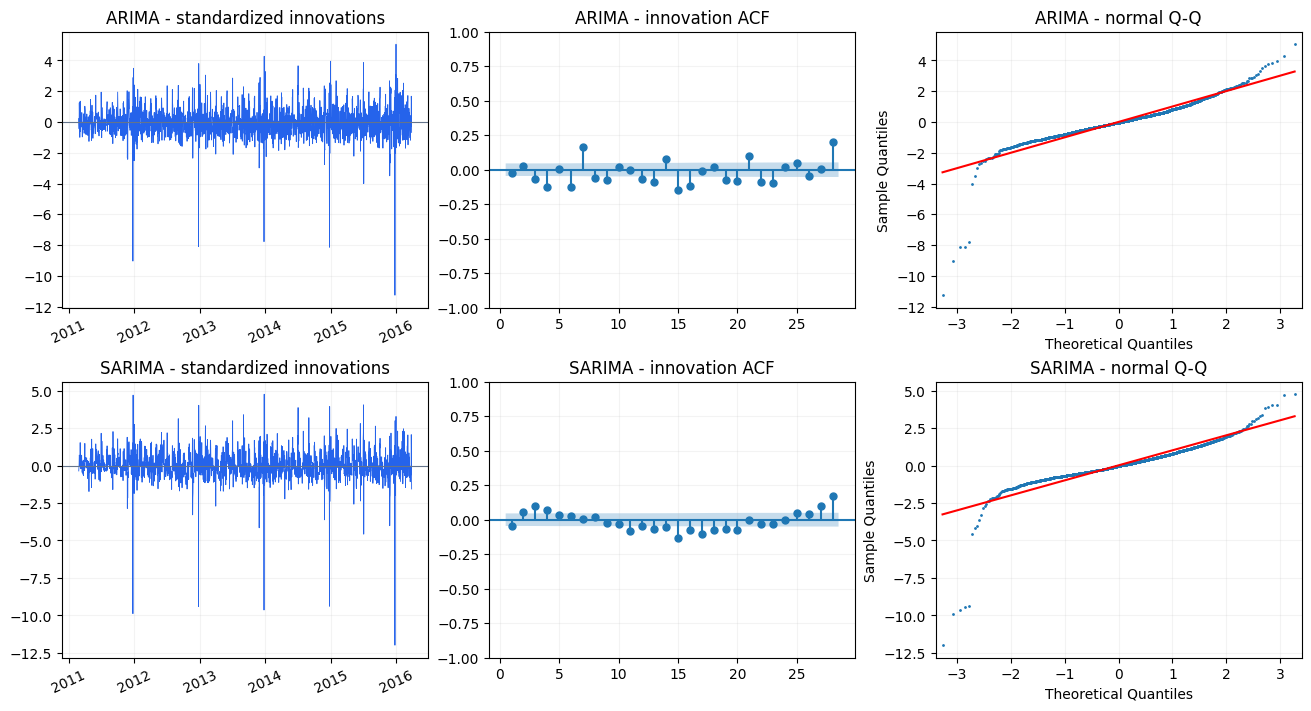

In [9]:
lb_rows = []
parameter_rows = []
fit_summaries = []
residual_info = {}
fig_residuals, axes = plt.subplots(2, 3, figsize=(13, 7), layout='constrained')
for index, family in enumerate(['ARIMA', 'SARIMA']):
    chosen = best_validation[family]
    fitted, config = chosen['fit'], chosen['config']
    burn = max(28, int(fitted.loglikelihood_burn))
    innovations = np.asarray(fitted.filter_results.standardized_forecasts_error[0])[burn:]
    require(np.isfinite(innovations).all(), 'Non-finite standardized innovations.')
    model_df = int(config['p'] + config['q'] + config['P'] + config['Q'])
    require(min(LB_LAGS) > model_df, 'Ljung-Box lag must exceed model degrees of freedom.')
    lb = acorr_ljungbox(innovations, lags=list(LB_LAGS), model_df=model_df, return_df=True)
    for lag, row in lb.iterrows():
        lb_rows.append({'family': family, 'config_id': config['config_id'],
                        'lag': int(lag), 'model_df': model_df, 'discarded_start_rows': burn,
                        'innovation_rows': len(innovations), 'lb_stat': float(row['lb_stat']),
                        'lb_pvalue': float(row['lb_pvalue']),
                        'reject_no_autocorrelation': bool(row['lb_pvalue'] < ALPHA)})
    intervals = np.asarray(fitted.conf_int(alpha=ALPHA))
    for j, name in enumerate(fitted.param_names):
        parameter_rows.append({'family': family, 'config_id': config['config_id'],
                               'parameter': name, 'estimate': float(fitted.params[j]),
                               'std_error': float(fitted.bse[j]),
                               'lower_95': float(intervals[j, 0]),
                               'upper_95': float(intervals[j, 1])})
    residual_info[family] = {'burn_in': burn, 'observations': len(innovations),
                             'model_df': model_df,
                             'any_ljung_box_rejection': bool((lb['lb_pvalue'] < ALPHA).any())}
    fit_summaries.append(f"{family}: {config['config_id']}\n{fitted.summary()}\n")
    axes[index, 0].plot(development['date'].iloc[burn:1885], innovations,
                         linewidth=0.6, color='#2563eb')
    axes[index, 0].axhline(0, color='#64748b', linewidth=0.8)
    axes[index, 0].set_title(f'{family} - standardized innovations')
    axes[index, 0].tick_params(axis='x', labelrotation=25)
    plot_acf(innovations, lags=28, zero=False, alpha=ALPHA,
              ax=axes[index, 1], title=f'{family} - innovation ACF')
    qqplot(innovations, line='s', ax=axes[index, 2], marker='.', markersize=2)
    axes[index, 2].set_title(f'{family} - normal Q-Q')
    for ax in axes[index]:
        ax.grid(alpha=0.15)
ljung_box = pd.DataFrame(lb_rows)
parameters = pd.DataFrame(parameter_rows)
print(ljung_box.to_string(index=False, formatters={
    'lb_stat': lambda value: f'{value:.4f}',
    'lb_pvalue': lambda value: f'{value:.3e}'}))
print('Diagnostic rejections, if present, remain reported; numerical PASS is not model adequacy.')
plt.show()
plt.close(fig_residuals)

## 7. Compare Validation forecasts

The plot includes the weekly baseline and the selected ARIMA/SARIMA models.
All four baselines remain in the comparison table. These are Validation
forecasts from the same fixed origin, not predictions evaluated on Test.

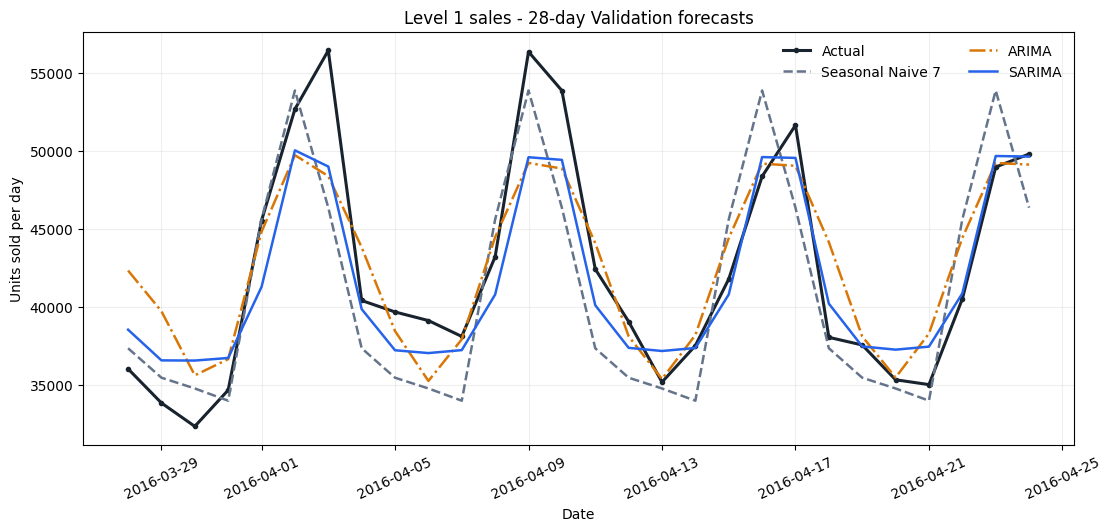

In [10]:
fig_validation, ax = plt.subplots(figsize=(11, 5.2), layout='constrained')
actual_frame = frames['val']
ax.plot(pd.to_datetime(actual_frame['date']), actual_frame['total_sales'],
        color='#18232e', marker='o', markersize=3, linewidth=2.2, label='Actual')
for name, color, style in [('Seasonal Naive 7', '#64748b', '--'),
                            ('ARIMA', '#d97706', '-.'), ('SARIMA', '#2563eb', '-')]:
    subset = predictions[(predictions['fold'] == 3) & (predictions['model'] == name)]
    ax.plot(pd.to_datetime(subset['date']), subset['prediction'],
            color=color, linestyle=style, linewidth=1.8, label=name)
ax.set(title='Level 1 sales - 28-day Validation forecasts',
        xlabel='Date', ylabel='Units sold per day')
ax.grid(alpha=0.2)
ax.legend(frameon=False, ncol=2)
ax.tick_params(axis='x', labelrotation=25)
plt.show()
plt.close(fig_validation)

## 8. Save results and the download bundle

Save the complete candidate search, six-model development comparison,
daily forecasts, selected coefficients, residual diagnostics, figures and
configuration manifest. The manifest fixes the chosen orders for later work;
this notebook does not refit on Train+Validation or open Test.

`PASS` means required calculations and files were completed consistently.
It does not mean every candidate converged, every residual test passed, or
either statistical model beat the baselines. Failed candidates and remaining
residual structure must be discussed using the saved evidence.

In [11]:
table_dir = output_dir / '04_Outputs_and_Artifacts' / 'table'
figure_dir = output_dir / '04_Outputs_and_Artifacts' / 'figures'
prediction_dir = output_dir / '02_Data' / 'predictions'
for directory in [table_dir, figure_dir, prediction_dir]:
    directory.mkdir(parents=True, exist_ok=True)
files_to_package = []
for name, table in [('arima_candidate_search.csv', search_results),
                    ('arima_cv_scores.csv', cv_scores), ('arima_summary.csv', summary),
                    ('arima_residual_ljung_box.csv', ljung_box),
                    ('arima_parameters.csv', parameters)]:
    path = table_dir / name
    table.to_csv(path, index=False, float_format='%.12g')
    files_to_package.append(path)
prediction_path = prediction_dir / 'arima_cv_predictions.csv'
predictions.to_csv(prediction_path, index=False, float_format='%.12g')
files_to_package.append(prediction_path)
for name, figure in [('arima_validation_forecasts.png', fig_validation),
                      ('arima_residual_diagnostics.png', fig_residuals)]:
    path = figure_dir / name
    figure.savefig(path, dpi=300, bbox_inches='tight')
    files_to_package.append(path)
manifest = {
    'selection_metric': 'Validation RMSSE',
    'tie_breakers': ['parameter_count', 'config_id'],
    'selection_origin': 1885, 'forecast_horizon': HORIZON,
    'target_divisor': SALES_SCALE, 'enforce_stationarity': True,
    'enforce_invertibility': True,
    'selected_candidates': [best_validation[family]['config'] for family in ['ARIMA', 'SARIMA']],
    'test_labels_read': False,
}
manifest_path = output_dir / '04_Outputs_and_Artifacts' / 'arima_selected_configurations.json'
manifest_path.write_text(json.dumps(manifest, indent=2, allow_nan=False) + '\n')
files_to_package.append(manifest_path)
summaries_path = output_dir / '04_Outputs_and_Artifacts' / 'arima_fit_summaries.txt'
summaries_path.write_text('\n'.join(fit_summaries), encoding='utf-8')
files_to_package.append(summaries_path)
report = {
    'status': 'PASS', 'checked_at_utc': datetime.now(timezone.utc).isoformat(),
    'python': platform.python_version(), 'random_seed': SEED,
    'packages': {package: metadata.version(package) for package in
                 ['numpy', 'pandas', 'scipy', 'matplotlib', 'statsmodels', 'threadpoolctl']},
    'files_read': list(FILENAMES), 'test_labels_read': False,
    'test_forecasts_computed': False, 'forecast_horizon': HORIZON,
    'data_fingerprints': {item['file']: item['table_sha256'] for item in input_inventory},
    'origins': list(ORIGINS), 'fold_plan': fold_plan.to_dict(orient='records'),
    'candidate_count': len(candidates),
    'eligible_candidate_count': int(search_results['eligible'].sum()),
    'excluded_candidate_count': int((~search_results['eligible']).sum()),
    'explicit_p7_arima_candidates': 6,
    'candidate_selection': 'Validation RMSSE; then parameter count and config_id',
    'information_criteria_comparison': 'Within fixed family and differencing pair (d,D)',
    'target_divisor': SALES_SCALE, 'optimizer': 'L-BFGS',
    'optimizer_iteration_limits': list(MAX_ITERATIONS), 'numerical_library_threads': 1,
    'selected_candidates': manifest['selected_candidates'],
    'selected_candidate_diagnostics': residual_info,
    'comparison_summary': summary.to_dict(orient='records'),
    'cv_score_records': len(cv_scores), 'forecast_records': len(predictions),
    'clipped_forecasts': int(cv_scores['clipped_count'].sum()),
    'clipped_fraction': float(cv_scores['clipped_count'].sum() / len(predictions)),
    'limitations': [
        'Candidate grids are bounded rather than exhaustive.',
        'Model selection and stability summaries share the Validation window.',
        'Three nearby development windows do not cover all annual seasons.',
        'Information criteria across different differencing orders are not ranked together.',
        'Residual diagnostics can flag inadequacy despite a numerically completed run.',
        'No independent Test performance is reported.',
    ],
    'run_seconds_before_packaging': float(perf_counter() - RUN_STARTED),
}
report_path = output_dir / '04_Outputs_and_Artifacts' / 'arima_run_report.json'
report_path.write_text(json.dumps(report, ensure_ascii=False, indent=2, allow_nan=False) + '\n')
files_to_package.append(report_path)
archive_path = output_dir / '03_arima_sarima_results.zip'
with ZipFile(archive_path, 'w', compression=ZIP_DEFLATED) as archive:
    for path in files_to_package:
        archive.write(path, arcname=path.relative_to(output_dir))
require(len(files_to_package) == 11, 'Expected eleven result files.')
print('ARIMA/SARIMA CHECK PASSED')
print(f'Candidates: {len(candidates)}; selected families: 2; folds: 3; forecast rows: {len(predictions)}')
print(f'Excluded candidate fits: {report["excluded_candidate_count"]}')
print(f'Download bundle: {archive_path.resolve()}')
print(summary[['model', 'config_id', 'validation_rmsse', 'mean_rmsse', 'std_rmsse']]
      .round(4).to_string(index=False))

ARIMA/SARIMA CHECK PASSED
Candidates: 64; selected families: 2; folds: 3; forecast rows: 504
Excluded candidate fits: 0
Download bundle: /kaggle/working/03_arima_sarima_results.zip
           model              config_id  validation_rmsse  mean_rmsse  std_rmsse
          SARIMA sarima_1_1_1_1_1_1_7_n            0.4873      0.6030     0.1707
           ARIMA          arima_7_1_2_t            0.5982      0.6040     0.0170
Seasonal Naive 7       seasonal_naive_7            0.6677      0.7519     0.1542
          SMA-28      moving_average_28            1.2001      1.1643     0.0603
           SMA-7       moving_average_7            1.2165      1.2238     0.0533
           Naive                  naive            1.3843      1.7027     0.2758


## References

- Finalized IS403 project plan: Box-Jenkins procedure, temporal split, RMSSE,
  residual diagnostics and bounded-search risk mitigation.
- Course Chapter 5: ARIMA/SARIMA identification, estimation and diagnostics.
- Hyndman & Athanasopoulos, *Forecasting: Principles and Practice*, Chapter 9:
  https://otexts.com/fpp3/arima.html
- statsmodels official APIs:
  [ARIMA](https://www.statsmodels.org/stable/generated/statsmodels.tsa.arima.model.ARIMA.html),
  [fit](https://www.statsmodels.org/stable/generated/statsmodels.tsa.arima.model.ARIMA.fit.html),
  [Ljung-Box](https://www.statsmodels.org/stable/generated/statsmodels.stats.diagnostic.acorr_ljungbox.html).